Dataset shape: (1000, 10)


,Record_ID,Machine_Type,Shift,Operating_Hours,Temperature_C,Vibration_mm_s,Pressure_bar,RPM,Motor_Current_A,Remaining_Useful_Life_Hours
0,REC0001,Type_C,Day,2622.075462,76.726313,NaN,NaN,1988.802669,20.437653,185.342934
1,REC0002,Type_B,Evening,3108.332006,100.543880,4.063364,36.132563,2377.468965,20.362805,159.117283
2,REC0003,Type_C,Day,5482.938567,66.774514,10.374014,NaN,1390.828027,20.194577,103.480551
3,REC0004,Type_B,Day,5293.731365,84.564906,4.122366,26.259142,1925.167887,21.764727,132.005109
4,REC0005,Type_A,Evening,2375.834607,69.653203,2.139867,29.605992,1474.530712,18.648339,226.371969



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 10 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Record_ID                    1000 non-null   object 
 1   Machine_Type                 1000 non-null   object 
 2   Shift                        990 non-null    object 
 3   Operating_Hours              1000 non-null   float64
 4   Temperature_C                975 non-null    float64
 5   Vibration_mm_s               980 non-null    float64
 6   Pressure_bar                 980 non-null    float64
 7   RPM                          1000 non-null   float64
 8   Motor_Current_A              985 non-null    float64
 9   Remaining_Useful_Life_Hours  1000 non-null   float64
dtypes: float64(7), object(3)
memory usage: 78.3+ KB

Missing values:


,0
Temperature_C,25
Vibration_mm_s,20
Pressure_bar,20
Motor_Current_A,15
Shift,10
Record_ID,0
Machine_Type,0
Operating_Hours,0
RPM,0
Remaining_Useful_Life_Hours,0



Descriptive statistics:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Record_ID,1000,1000,REC1000,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Machine_Type,1000,3,Type_A,402,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Shift,990,3,Day,363,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Operating_Hours,1000.0,NaN,NaN,NaN,4594.65682,2545.099094,116.686146,2412.189639,4631.109533,6751.93773,8954.812303
Temperature_C,975.0,NaN,NaN,NaN,83.787657,9.344708,56.604345,77.561281,84.045653,89.973022,113.464838
Vibration_mm_s,980.0,NaN,NaN,NaN,4.556511,2.37059,0.345741,2.846157,4.172676,5.759089,17.920347
Pressure_bar,980.0,NaN,NaN,NaN,30.139343,4.708081,10.466376,27.046894,30.105581,33.17973,44.631157
RPM,1000.0,NaN,NaN,NaN,1800.598928,185.034749,1248.683738,1682.549957,1789.128525,1930.171446,2377.468965
Motor_Current_A,985.0,NaN,NaN,NaN,17.263249,2.289162,10.514841,15.747052,17.235654,18.883881,24.468578
Remaining_Useful_Life_Hours,1000.0,NaN,NaN,NaN,187.372835,54.402674,86.214215,134.910785,185.181607,250.0,250.0



Duplicate rows: 0


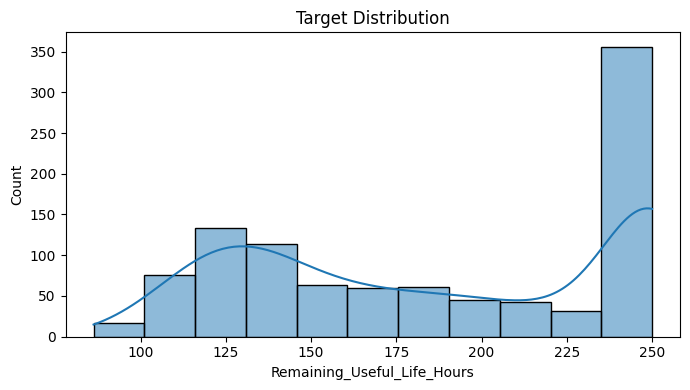

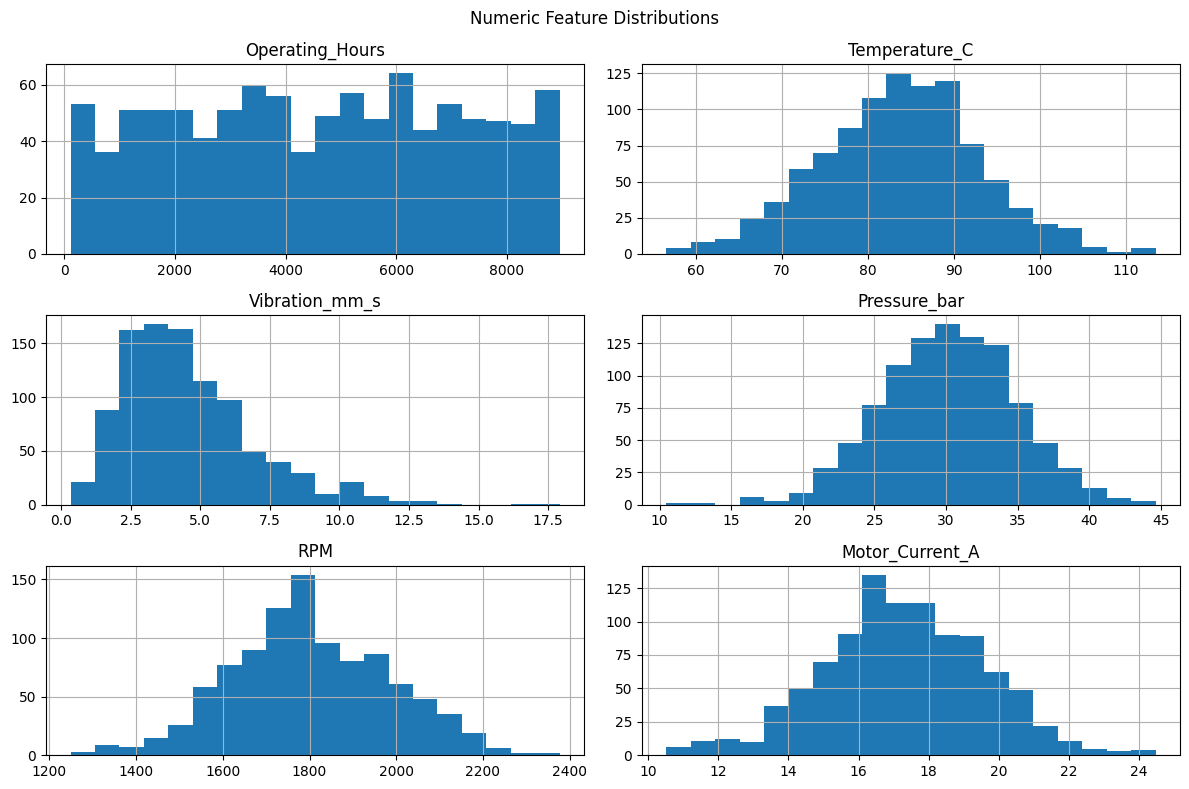

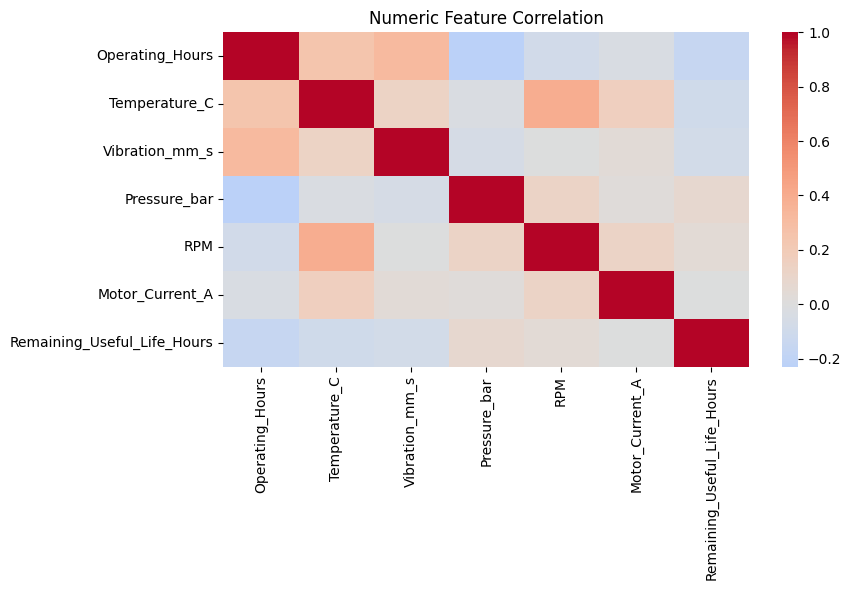

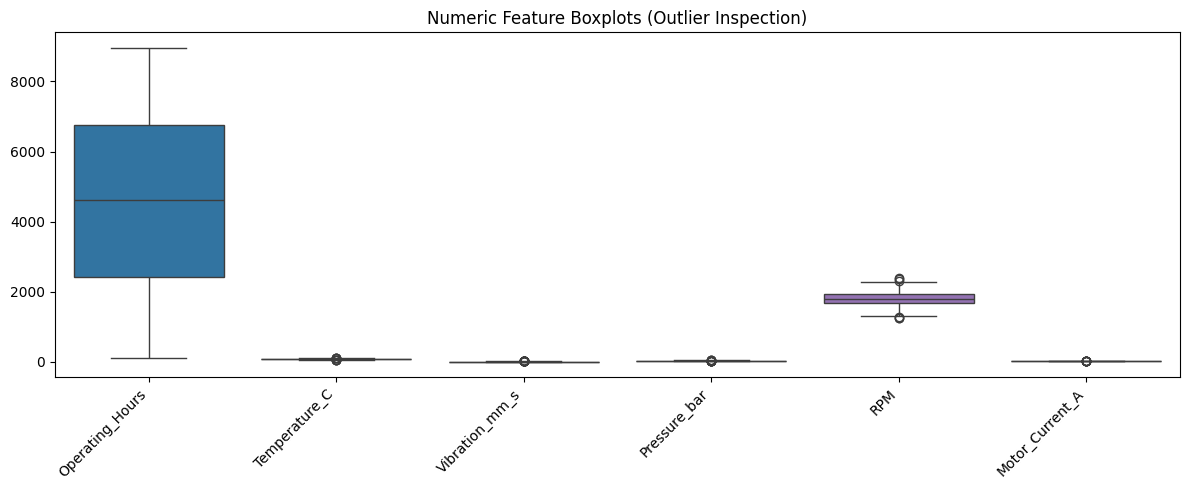


Record_ID value counts:


,count
Record_ID,
REC1000,1
REC0001,1
REC0002,1
REC0003,1
REC0004,1
REC0005,1
REC0006,1
REC0007,1
REC0984,1



Machine_Type value counts:


,count
Machine_Type,
Type_A,402
Type_B,341
Type_C,257



Shift value counts:


,count
Shift,
Day,363
Evening,332
Night,295
NaN,10


Identifier columns removed: ['Record_ID']
Numeric features: ['Operating_Hours', 'Temperature_C', 'Vibration_mm_s', 'Pressure_bar', 'RPM', 'Motor_Current_A']
Categorical features: ['Machine_Type', 'Shift']
Parameter combinations per search: 216
Criterion values tested: ['squared_error', 'absolute_error', 'friedman_mse']


In [ ]:
import glob
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import ttest_rel
from sklearn.model_selection import KFold, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
TARGET = "Remaining_Useful_Life_Hours"

# ---------- 1. LOAD CSV ----------
csv_files = glob.glob("*.csv")
if len(csv_files) == 1:
    file_name = csv_files[0]
elif len(csv_files) > 1:
    print("CSV files found:", csv_files)
    file_name = input("Enter the CSV filename to use: ").strip()
else:
    file_name = input("Enter the CSV file path: ").strip()

df = pd.read_csv(file_name)
print("Dataset shape:", df.shape)
display(df.head())
print("\nDataset information:")
df.info()
print("\nMissing values:")
display(df.isnull().sum().sort_values(ascending=False))
print("\nDescriptive statistics:")
display(df.describe(include="all").T)
print("\nDuplicate rows:", df.duplicated().sum())

# ---------- 2. SIMPLE EDA ----------
if TARGET not in df.columns:
    print("Available columns:", list(df.columns))
    raise ValueError("Change TARGET to the exact regression target column name.")

df[TARGET] = pd.to_numeric(df[TARGET], errors="coerce")
df = df.drop_duplicates().dropna(subset=[TARGET]).copy()

plt.figure(figsize=(7, 4))
sns.histplot(df[TARGET], kde=True)
plt.title("Target Distribution")
plt.xlabel(TARGET)
plt.tight_layout()
plt.show()

numeric_for_eda = df.select_dtypes(include=np.number).drop(columns=[TARGET], errors="ignore")
if len(numeric_for_eda.columns) > 0:
    numeric_for_eda.hist(figsize=(12, 8), bins=20)
    plt.suptitle("Numeric Feature Distributions")
    plt.tight_layout()
    plt.show()

    plt.figure(figsize=(9, 6))
    sns.heatmap(df.select_dtypes(include=np.number).corr(), cmap="coolwarm", center=0)
    plt.title("Numeric Feature Correlation")
    plt.tight_layout()
    plt.show()

    plt.figure(figsize=(12, 5))
    sns.boxplot(data=numeric_for_eda)
    plt.title("Numeric Feature Boxplots (Outlier Inspection)")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

for col in df.select_dtypes(exclude=np.number).columns:
    print(f"\n{col} value counts:")
    display(df[col].value_counts(dropna=False).head(10))

# ---------- 3. PREPARE X AND y ----------
id_cols = [
    c for c in df.columns
    if c != TARGET and (
        c.lower() in ["id", "record_id", "recordid", "machine_id"] or
        ("id" in c.lower() and df[c].nunique(dropna=False) >= 0.9 * len(df))
    )
]
print("Identifier columns removed:", id_cols)

X = df.drop(columns=[TARGET] + id_cols)
y = df[TARGET].astype(float)

numeric_cols = X.select_dtypes(include=np.number).columns.tolist()
categorical_cols = X.select_dtypes(exclude=np.number).columns.tolist()
print("Numeric features:", numeric_cols)
print("Categorical features:", categorical_cols)

try:
    encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
except TypeError:  # compatibility with older scikit-learn
    encoder = OneHotEncoder(handle_unknown="ignore", sparse=False)

numeric_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", encoder)
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipe, numeric_cols),
    ("cat", categorical_pipe, categorical_cols)
], remainder="drop")

# PCA is applied only to scaled numeric columns; one-hot categorical columns pass through.
pca_preprocessor = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("pca", PCA(n_components=0.95, random_state=RANDOM_STATE))
    ]), numeric_cols),
    ("cat", categorical_pipe, categorical_cols)
], remainder="drop")

# ---------- 4. HYPERPARAMETER GRID ----------
# Justification:
# n_estimators controls the number of trees.
# criterion selects the split-quality / leaf-value objective.
# max_depth controls tree complexity.
# min_samples_split and min_samples_leaf help reduce overfitting.
# "poisson" is another sklearn criterion, omitted here to keep the search manageable;
# it is intended for non-negative targets.
param_grid = {
    "model__n_estimators": [100, 200],
    "model__criterion": ["squared_error", "absolute_error", "friedman_mse"],
    "model__max_depth": [None, 5, 10, 20],
    "model__min_samples_split": [2, 5, 10],
    "model__min_samples_leaf": [1, 2, 4]
}
n_combinations = (
    len(param_grid["model__n_estimators"]) *
    len(param_grid["model__criterion"]) *
    len(param_grid["model__max_depth"]) *
    len(param_grid["model__min_samples_split"]) *
    len(param_grid["model__min_samples_leaf"])
)
print("Parameter combinations per search:", n_combinations)
print("Criterion values tested:", param_grid["model__criterion"])

# ---------- 5. NESTED EVALUATION: SAME 5 OUTER FOLDS ----------
# Hyperparameter tuning is performed only within each outer training fold.
outer_cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
results = []
fold_predictions = {}

def mape_percent(y_true, y_pred):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    mask = np.abs(y_true) > 1e-8
    if not np.any(mask):
        return np.nan
    return np.mean(np.abs((y_true[mask] - y_pred[mask]) / y_true[mask])) * 100

for fold, (train_idx, valid_idx) in enumerate(outer_cv.split(X, y), start=1):
    X_train, X_valid = X.iloc[train_idx], X.iloc[valid_idx]
    y_train, y_valid = y.iloc[train_idx], y.iloc[valid_idx]

    for name, prep in [("Without PCA", preprocessor), ("With PCA", pca_preprocessor)]:
        pipe = Pipeline([
            ("preprocess", prep),
            ("model", RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=1))
        ])

        grid = GridSearchCV(
            estimator=pipe,
            param_grid=param_grid,
            scoring="neg_root_mean_squared_error",
            cv=3,
            n_jobs=-1,
            refit=True
        )

        start = time.time()
        grid.fit(X_train, y_train)
        elapsed = time.time() - start

        best_model = grid.best_estimator_
        train_pred = best_model.predict(X_train)
        valid_pred = best_model.predict(X_valid)

        train_rmse = np.sqrt(mean_squared_error(y_train, train_pred))
        valid_rmse = np.sqrt(mean_squared_error(y_valid, valid_pred))
        valid_mae = mean_absolute_error(y_valid, valid_pred)
        valid_r2 = r2_score(y_valid, valid_pred)
        valid_mape = mape_percent(y_valid, valid_pred)

        results.append({
            "Fold": fold,
            "Model": name,
            "Train_RMSE": train_rmse,
            "Validation_RMSE": valid_rmse,
            "MAE": valid_mae,
            "R2": valid_r2,
            "MAPE_percent": valid_mape,
            "Train_Validation_RMSE_Gap": valid_rmse - train_rmse,
            "Best_Inner_CV_RMSE": -grid.best_score_,
            "Best_Params": grid.best_params_,
            "Runtime_seconds": elapsed
        })
        fold_predictions[(name, fold)] = (y_valid.to_numpy(), valid_pred)

        print(f"\nFold {fold} | {name}")
        print("Best parameters:", grid.best_params_)
        print("Best inner CV RMSE:", round(-grid.best_score_, 4))
        print("Train RMSE:", round(train_rmse, 4))
        print("Validation RMSE:", round(valid_rmse, 4))
        print("Validation MAE:", round(valid_mae, 4))
        print("Validation R²:", round(valid_r2, 4))
        print("Validation MAPE (%):", round(valid_mape, 4))
        print("Runtime (seconds):", round(elapsed, 2))

results_df = pd.DataFrame(results)
print("\nFOLD-WISE RESULTS")
display(results_df[[
    "Fold", "Model", "Train_RMSE", "Validation_RMSE", "MAE", "R2",
    "MAPE_percent", "Train_Validation_RMSE_Gap", "Best_Inner_CV_RMSE",
    "Runtime_seconds"
]].round(4))

print("\nBEST HYPERPARAMETERS FOR EVERY FOLD")
display(results_df[["Fold", "Model", "Best_Params"]])

metric_cols = [
    "Validation_RMSE", "MAE", "R2", "MAPE_percent",
    "Train_Validation_RMSE_Gap", "Runtime_seconds"
]
summary = results_df.groupby("Model")[metric_cols].agg(["mean", "std"]).round(4)
print("\nMEAN AND STANDARD DEVIATION ACROSS THE 5 OUTER FOLDS")
display(summary)

print("\nTotal tuning runtime (seconds):")
display(results_df.groupby("Model")["Runtime_seconds"].sum().round(2))

# ---------- 6. PCA EXPLAINED VARIANCE ----------
# Descriptive plot only; predictive PCA above is fitted within each fold.
if len(numeric_cols) >= 1:
    eda_numeric = SimpleImputer(strategy="median").fit_transform(X[numeric_cols])
    eda_scaled = StandardScaler().fit_transform(eda_numeric)
    pca_eda = PCA().fit(eda_scaled)
    cumulative = np.cumsum(pca_eda.explained_variance_ratio_)
    plt.figure(figsize=(7, 4))
    plt.plot(range(1, len(cumulative) + 1), cumulative, marker="o")
    plt.axhline(0.95, linestyle="--", label="95% variance")
    plt.xlabel("Number of Principal Components")
    plt.ylabel("Cumulative Explained Variance")
    plt.title("PCA Cumulative Explained Variance")
    plt.legend()
    plt.tight_layout()
    plt.show()
    print("Components needed for at least 95% variance:", np.argmax(cumulative >= 0.95) + 1)

# ---------- 7. FOLD RMSE COMPARISON ----------
pivot_rmse = results_df.pivot(index="Fold", columns="Model", values="Validation_RMSE")
display(pivot_rmse.round(4))

plt.figure(figsize=(7, 4))
for col in pivot_rmse.columns:
    plt.plot(pivot_rmse.index, pivot_rmse[col], marker="o", label=col)
plt.xlabel("Outer Fold")
plt.ylabel("Validation RMSE (lower is better)")
plt.title("Random Forest Regressor: With vs Without PCA")
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 4))
sns.boxplot(data=results_df, x="Model", y="Validation_RMSE")
sns.stripplot(data=results_df, x="Model", y="Validation_RMSE", color="black", alpha=0.6)
plt.title("Fold-wise Validation RMSE Distribution")
plt.tight_layout()
plt.show()

# ---------- 8. PAIRED TWO-SIDED T-TEST ----------
# H0: mean paired RMSE difference = 0; H1: mean paired RMSE difference != 0
no_pca = pivot_rmse["Without PCA"].to_numpy()
with_pca = pivot_rmse["With PCA"].to_numpy()
t_stat, p_value = ttest_rel(with_pca, no_pca)
alpha = 0.05

print("\nPAIRED TWO-SIDED T-TEST")
print("H0: Mean paired RMSE difference (With PCA - Without PCA) = 0")
print("H1: Mean paired RMSE difference (With PCA - Without PCA) != 0")
print("Alpha:", alpha)
print("t-statistic:", round(t_stat, 5))
print("p-value:", round(p_value, 6))
if p_value < alpha:
    print("Decision: Reject H0; difference is statistically significant at 5%.")
else:
    print("Decision: Fail to reject H0; insufficient evidence of a significant difference at 5%.")

# ---------- 9. ACTUAL VS PREDICTED AND RESIDUAL PLOTS ----------
for name in ["Without PCA", "With PCA"]:
    actual, predicted = fold_predictions[(name, 5)]
    residuals = actual - predicted

    plt.figure(figsize=(5, 5))
    plt.scatter(actual, predicted, alpha=0.7)
    low = min(actual.min(), predicted.min())
    high = max(actual.max(), predicted.max())
    plt.plot([low, high], [low, high], linestyle="--")
    plt.xlabel("Actual RUL")
    plt.ylabel("Predicted RUL")
    plt.title(f"Actual vs Predicted — {name} (Fold 5)")
    plt.tight_layout()
    plt.show()

    plt.figure(figsize=(6, 4))
    plt.scatter(predicted, residuals, alpha=0.7)
    plt.axhline(0, linestyle="--")
    plt.xlabel("Predicted RUL")
    plt.ylabel("Residual (Actual - Predicted)")
    plt.title(f"Residual Plot — {name} (Fold 5)")
    plt.tight_layout()
    plt.show()

# ---------- 10. FEATURE IMPORTANCE ----------
# Show feature importance from a final tuned model fit on the full dataset.
# This is descriptive only; use outer-fold results for unbiased performance estimates.
final_pipe = Pipeline([
    ("preprocess", preprocessor),
    ("model", RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=1))
])
final_grid = GridSearchCV(
    final_pipe,
    param_grid=param_grid,
    scoring="neg_root_mean_squared_error",
    cv=5,
    n_jobs=-1
)
final_grid.fit(X, y)
print("\nFINAL FULL-DATASET BEST PARAMETERS (for deployment / feature-importance inspection):")
print(final_grid.best_params_)
print("Full-data CV RMSE:", round(-final_grid.best_score_, 4))

best_final = final_grid.best_estimator_
feature_names = best_final.named_steps["preprocess"].get_feature_names_out()
importances = best_final.named_steps["model"].feature_importances_
importance_df = pd.DataFrame({"Feature": feature_names, "Importance": importances})
importance_df = importance_df.sort_values("Importance", ascending=False).head(15)
display(importance_df)

plt.figure(figsize=(8, 5))
sns.barplot(data=importance_df, x="Importance", y="Feature")
plt.title("Top Random Forest Feature Importances")
plt.tight_layout()
plt.show()

# ---------- 11. CONCLUSION GUIDE ----------
mean_rmse = results_df.groupby("Model")["Validation_RMSE"].mean()
print("\nCONCLUSION GUIDE")
print("Lower mean validation RMSE is better. Lower mean RMSE in this run:", mean_rmse.idxmin())
print("Compare MAE and R² as well; mention train-validation RMSE gap and runtime.")
print("Random Forest averages predictions from many decision trees and often reduces variance compared with one tree.")
print("PCA may not improve tree-based models and can reduce feature-level interpretability.")
print("Potential improvements: tune max_features, use repeated CV, engineer domain features, and compare gradient boosting.")
print("MAPE can be unstable when actual target values are zero or near zero.")